# Step 2: GRPO smoke test at 0.5B

Plain GRPO (reward = answer F1) through the multi-turn search loop, with retrieved tokens masked from the loss. A 2-step dry run catches errors before the 30-step run.

In [ ]:
!pip install -q "trl[vllm]==1.16.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.2.2 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.


In [ ]:
PROJECT = "/content/drive/MyDrive/search_or_think"
import os, sys
from google.colab import drive
drive.mount("/content/drive")
CODE, DATA, OUT = f"{PROJECT}/code", f"{PROJECT}/data", f"{PROJECT}/outputs"
sys.path.insert(0, CODE)
import torch, trl, vllm
print("trl", trl.__version__, "| vllm", vllm.__version__, "| GPU", torch.cuda.get_device_name(0))

Mounted at /content/drive
trl 1.16.0 | vllm 0.31.0 | GPU NVIDIA A100-SXM4-40GB


## Updated code

In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/sot/analysis.py
"""Metrics over saved runs: accuracy tables, p(q) distribution, QOR, SOR, and the SAAS vs Soft-SAAS signal check."""
import collections
import json
import math
import random

from .rewards import estimate_boundary, penalty_saas, penalty_soft
from .scoring import has_answer, norm_title


def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]


def mean(xs):
    xs = list(xs)
    return sum(xs) / len(xs) if xs else math.nan


def by_dataset(rows):
    g = collections.defaultdict(list)
    for r in rows:
        g[r["dataset"]].append(r)
    return dict(sorted(g.items()))


def summarize(rows):
    return {ds: {"n": len(v), "em": mean(r["em"] for r in v), "f1": mean(r["f1"] for r in v),
                 "searches": mean(r["n_search"] for r in v), "format_ok": mean(r["format_ok"] for r in v)}
            for ds, v in by_dataset(rows).items()}


def p_by_id(closed_rows, col="em"):
    """col: "em" (strict) or "cover" (gold answer contained in the prediction)."""
    d = collections.defaultdict(list)
    for r in closed_rows:
        d[r["id"]].append(r[col] >= 1.0)
    return {k: sum(v) / len(v) for k, v in d.items()}


def enriched_sample(recs, pmap, n, mid_frac=1 / 3, seed=0):
    """n questions with about mid_frac at 0 < p(q) < 1 (fewer if the pool has fewer); the rest keep the
    pool's own mix of p(q) = 0 and p(q) = 1."""
    rng = random.Random(seed)
    mid = [r for r in recs if 0 < pmap[r["id"]] < 1]
    rest = [r for r in recs if not 0 < pmap[r["id"]] < 1]
    rng.shuffle(mid)
    rng.shuffle(rest)
    k = min(len(mid), round(n * mid_frac))
    out = mid[:k] + rest[:n - k]
    out += mid[k:k + n - len(out)]  # too few p(q) = 0 or 1 questions: top up with in-between ones
    rng.shuffle(out)
    return out


def p_distribution(pmap, recs):
    out = {}
    for ds, v in by_dataset(recs).items():
        ps = [pmap[r["id"]] for r in v if r["id"] in pmap]
        out[ds] = {"n": len(ps), "hist": dict(sorted(collections.Counter(round(p, 2) for p in ps).items())),
                   "p0": mean(p == 0 for p in ps), "mid": mean(0 < p < 1 for p in ps), "p1": mean(p == 1 for p in ps)}
    return out


def qor(agent_rows, pmap, thr=0.5):
    """Question level over search: share of questions the base model can answer without search
    (p(q) >= thr) on which the policy still searches."""
    out = {}
    for ds, v in by_dataset(agent_rows).items():
        elig = [r for r in v if pmap.get(r["id"], 0.0) >= thr]
        out[ds] = {"eligible": len(elig), "qor": mean(r["n_search"] > 0 for r in elig)}
    return out


def _evidence_complete(rec, titles, text):
    if rec["dataset"] == "hotpotqa":
        gold = {norm_title(t) for t in rec.get("sup_titles", [])}
        return bool(gold) and gold <= titles
    return has_answer(text, rec["golds"])


def sor(agent_rows, recs_by_id):
    """Step level over search: share of searches issued after all gold evidence was already retrieved."""
    out = {}
    for ds, v in by_dataset(agent_rows).items():
        over = total = 0
        for r in v:
            rec, titles, text = recs_by_id[r["id"]], set(), ""
            for s in r["searches"]:
                over += _evidence_complete(rec, titles, text)
                total += 1
                titles |= {norm_title(t) for t in s["titles"]}
                text += " " + " ".join(s["texts"])
        out[ds] = {"searches": total, "sor": over / total if total else math.nan}
    return out


def boundary_signal(closed_rows, sampled_agent_rows):
    """How many questions can each reward penalise at all, and how often correct searching rollouts get penalised."""
    disabled, enabled, ds_of = collections.defaultdict(list), collections.defaultdict(list), {}
    for r in closed_rows:
        disabled[r["id"]].append(r["em"] >= 1.0)
    for r in sampled_agent_rows:
        enabled[r["id"]].append((r["em"] >= 1.0, r["n_search"]))
        ds_of[r["id"]] = r["dataset"]
    out = collections.defaultdict(lambda: {"questions": 0, "labels": collections.Counter(), "signal_saas": 0,
                                           "signal_soft": 0, "correct_searching": 0, "pen_saas": [], "pen_soft": []})
    for qid, rolls in enabled.items():
        if qid not in disabled:
            continue
        b = estimate_boundary(disabled[qid], rolls)
        o = out[ds_of[qid]]
        o["questions"] += 1
        o["labels"][b.label] += 1
        o["signal_saas"] += b.label != "Undetermined"
        o["signal_soft"] += b.p > 0 or b.n_min is not None
        for correct, n in rolls:
            if correct and n > 0:
                o["correct_searching"] += 1
                o["pen_saas"].append(penalty_saas(n, b))
                o["pen_soft"].append(penalty_soft(n, b))
    return {ds: {"questions": o["questions"], "labels": dict(o["labels"]),
                 "signal_saas": o["signal_saas"] / max(o["questions"], 1),
                 "signal_soft": o["signal_soft"] / max(o["questions"], 1),
                 "correct_searching_rollouts": o["correct_searching"],
                 "penalised_saas": mean(p > 0 for p in o["pen_saas"]),
                 "penalised_soft": mean(p > 0 for p in o["pen_soft"]),
                 "mean_pen_saas": mean(o["pen_saas"]), "mean_pen_soft": mean(o["pen_soft"])}
            for ds, o in sorted(out.items())}


Overwriting /content/drive/MyDrive/search_or_think/code/sot/analysis.py


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/sot/rollout.py
"""Token-level multi-turn rollout for GRPO. Same protocol as agent.run_agent, but it keeps the sampled token ids and
log probs, and marks retrieved <info> tokens with env_mask = 0 so they get no loss (TRL rollout_func contract)."""
from .agent import LIMIT_MSG, SEARCH_RE, format_info


def multi_turn_rollout(llm, tok, retrieve, prompts, sampling_params, max_searches=4, max_len=4096):
    """llm: a vLLM LLM; prompts: chat-formatted strings; sampling_params must stop at </search> and </answer>
    with include_stop_str_in_output=True and logprobs=0."""
    def enc(s):
        return tok(s, add_special_tokens=False)["input_ids"]

    n = len(prompts)
    P = [enc(p) for p in prompts]
    C, L, M = [[] for _ in range(n)], [[] for _ in range(n)], [[] for _ in range(n)]
    searches, over, done = [0] * n, [0] * n, [False] * n

    def env(i, text):  # tokens the model did not generate: no loss, no sampling log prob
        ids = enc(text)
        C[i] += ids
        L[i] += [None] * len(ids)
        M[i] += [0] * len(ids)

    for _ in range(max_searches + 2):
        for i in range(n):  # stop anything that could overflow the context window
            done[i] = done[i] or len(P[i]) + len(C[i]) + sampling_params.max_tokens > max_len
        act = [i for i in range(n) if not done[i]]
        if not act:
            break
        outs = llm.generate([{"prompt_token_ids": P[i] + C[i]} for i in act], sampling_params, use_tqdm=False)
        need, queries = [], []
        for i, o in zip(act, outs):
            g = o.outputs[0]
            ids = list(g.token_ids)
            C[i] += ids
            L[i] += [lp[t].logprob for lp, t in zip(g.logprobs, ids)]
            M[i] += [1] * len(ids)
            if not g.text.rstrip().endswith("</search>"):
                done[i] = True  # answered, or stopped without a tag
            elif searches[i] < max_searches:
                m = SEARCH_RE.findall(g.text)
                need.append(i)
                queries.append(m[-1].strip() if m else "")
            else:
                over[i] += 1
                done[i] = over[i] >= 2
                if not done[i]:
                    env(i, LIMIT_MSG)
        for i, res in zip(need, retrieve(queries) if queries else []):
            searches[i] += 1
            env(i, format_info(res))
    return {"prompt_ids": P, "completion_ids": C, "logprobs": L, "env_mask": M, "n_search": searches}


Writing /content/drive/MyDrive/search_or_think/code/sot/rollout.py


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/train_grpo.py
"""Plain GRPO (reward = answer F1) through the multi-turn search loop, with TRL 1.16 and colocated vLLM on one GPU.

Used for the smoke test: a short run that proves the trainer works, logs reward and search counts per step, and
measures seconds per step for the compute budget. Logs go to <project>/checkpoints/<run>/log.jsonl.
"""
import argparse
import json
import os
import sys
import time

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from sot.agent import agent_instruction, extract_answer
from sot.retrieval import Retriever
from sot.rollout import multi_turn_rollout
from sot.scoring import f1


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", default="Qwen/Qwen2.5-0.5B-Instruct")
    ap.add_argument("--project", required=True)
    ap.add_argument("--steps", type=int, default=30)
    ap.add_argument("--questions_per_step", type=int, default=8)
    ap.add_argument("--G", type=int, default=8, help="rollouts per question")
    ap.add_argument("--lr", type=float, default=1e-6)
    ap.add_argument("--tag", default="smoke")
    args = ap.parse_args()

    from datasets import Dataset
    from transformers import TrainerCallback
    from trl import GRPOConfig, GRPOTrainer
    from vllm import SamplingParams

    data = f"{args.project}/data"
    path = f"{data}/train_enriched.jsonl"
    path = path if os.path.exists(path) else f"{data}/hotpotqa_probe.jsonl"  # before step 1 has run
    rows = [json.loads(line) for line in open(path)]
    ds = Dataset.from_list([{"prompt": r["question"], "golds": r["golds"]} for r in rows]).shuffle(seed=0)
    out = f"{args.project}/checkpoints/grpo_{args.model.split('/')[-1]}_{args.tag}"
    os.makedirs(out, exist_ok=True)
    log_path = f"{out}/log.jsonl"
    open(log_path, "w").close()
    retrieve = Retriever(k=3)
    print("search server:", retrieve.health(), "| training questions:", path, len(rows))

    def f1_reward(completions, golds, n_search, **kw):
        kw["log_metric"]("searches_mean", sum(n_search) / len(n_search))
        # strict tag parsing: an answer outside <answer> tags earns nothing, which also teaches the format
        return [f1(extract_answer(c) or "", g) for c, g in zip(completions, golds)]

    def rollout(prompts, trainer):
        tok = trainer.processing_class
        chat = [tok.apply_chat_template([{"role": "user", "content": agent_instruction(q)}], tokenize=False,
                                        add_generation_prompt=True) + "<think>" for q in prompts]
        sp = SamplingParams(temperature=trainer.args.temperature, max_tokens=512, logprobs=0,
                            stop=["</search>", "</answer>"], include_stop_str_in_output=True)
        return multi_turn_rollout(trainer.vllm_generation.llm, tok, retrieve, chat, sp)

    class StepLog(TrainerCallback):
        t0 = time.time()

        def on_log(self, a, state, control, logs=None, **kw):
            with open(log_path, "a") as f:
                f.write(json.dumps({"step": state.global_step, "wall_s": time.time() - self.t0, **(logs or {})}) + "\n")

    # one generation batch per optimizer step: (G / 2) per device x (2 x questions) accumulation = G x questions
    cfg = GRPOConfig(output_dir=out, max_steps=args.steps, learning_rate=args.lr, num_generations=args.G,
                     per_device_train_batch_size=args.G // 2, gradient_accumulation_steps=2 * args.questions_per_step,
                     beta=0.0, temperature=1.0, bf16=True, gradient_checkpointing=True,
                     use_vllm=True, vllm_mode="colocate", vllm_gpu_memory_utilization=0.3, vllm_max_model_length=4096,
                     max_completion_length=3072, logging_steps=1, save_steps=25, save_total_limit=1, report_to="none")

    GRPOTrainer(model=args.model, reward_funcs=f1_reward, args=cfg, train_dataset=ds, rollout_func=rollout,
                callbacks=[StepLog()]).train()


if __name__ == "__main__":
    main()


Writing /content/drive/MyDrive/search_or_think/code/train_grpo.py


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/test_sot.py
"""Unit tests: python -m pytest -q test_sot.py"""
import pytest

from sot.agent import extract_answer, run_agent
from sot.analysis import boundary_signal, enriched_sample, p_by_id, qor, sor
from sot.rewards import (Boundary, WarmupTrigger, estimate_boundary, reward_fixed, reward_plain, reward_saas,
                         reward_soft_saas)
from sot.scoring import em, f1, has_answer

A = 0.1  # alpha


# scoring
def test_scoring():
    assert em("The Eiffel Tower!", ["eiffel tower"]) == 1.0
    assert f1("Paris France", ["Paris"]) == pytest.approx(2 / 3)
    assert f1("yes", ["no"]) == 0.0 and f1("no", ["no"]) == 1.0
    assert has_answer("Built in 1889 by Eiffel.", ["1889"]) and not has_answer("in 18890", ["1889"])


# rewards
def test_plain_and_fixed():
    assert reward_plain(0.7, 3) == 0.7
    assert reward_fixed(1.0, 2, 0.1) == pytest.approx(0.8)


def test_wrong_answers_never_penalised():
    for b in [Boundary(1.0, 0, "NoSearch"), Boundary(0.0, 1, "NeedSearch"), Boundary(0.5, 1, "Undetermined")]:
        assert reward_saas(0.5, 4, b, A) == 0.5
        assert reward_soft_saas(0.5, 4, b, A) == 0.5


def test_saas():
    assert reward_saas(1.0, 2, Boundary(1.0, 0, "NoSearch"), A) == pytest.approx(0.8)
    assert reward_saas(1.0, 3, Boundary(0.0, 1, "NeedSearch"), A) == pytest.approx(0.8)
    assert reward_saas(1.0, 1, Boundary(0.0, 1, "NeedSearch"), A) == 1.0
    assert reward_saas(1.0, 4, Boundary(0.5, 1, "Undetermined"), A) == 1.0  # no signal


def test_soft_saas_matches_saas_at_extremes_and_mixes_between():
    assert reward_soft_saas(1.0, 2, Boundary(1.0, 0, "NoSearch"), A) == pytest.approx(0.8)
    assert reward_soft_saas(1.0, 3, Boundary(0.0, 1, "NeedSearch"), A) == pytest.approx(0.8)
    # p = 0.5, N = 3, N_min = 1: 0.5*3 + 0.5*2 = 2.5 searches of penalty
    assert reward_soft_saas(1.0, 3, Boundary(0.5, 1, "Undetermined"), A) == pytest.approx(0.75)
    # never answerable and no correct searching rollout: only searches beyond the cap count
    assert reward_soft_saas(1.0, 4, Boundary(0.0, None, "Undetermined"), A) == 1.0
    assert reward_soft_saas(1.0, 2, Boundary(1.0, 0, "NoSearch"), A, w=0.0) == 1.0  # warm up off


def test_estimate_boundary():
    assert estimate_boundary([True] * 4, [(True, 1)]).label == "NoSearch"
    b = estimate_boundary([False] * 4, [(False, 4), (True, 2), (True, 1)])
    assert (b.label, b.n_min, b.p) == ("NeedSearch", 1, 0.0)
    b = estimate_boundary([True, False, False, False], [(True, 2)])
    assert (b.label, b.p) == ("Undetermined", 0.25)
    assert estimate_boundary([False] * 4, [(False, 3)]).label == "Undetermined"


def test_warmup_trigger():
    w = WarmupTrigger(window=5, eps=0.01, ramp=10, ma=3)
    ws = [w.update(min(0.05 * t, 0.6)) for t in range(60)]  # rises for 12 steps, then flat
    assert w.trigger_step is not None and 12 < w.trigger_step < 30
    assert all(x == 0.0 for x in ws[:w.trigger_step + 1])
    assert ws[-1] == 1.0 and ws == sorted(ws)


# agent loop with a fake model and retriever
def fake_retrieve(queries):
    return [[{"title": f"T_{q}", "text": f"text about {q}"}] for q in queries]


def make_generate(script):
    """script: prompt keyword -> list of outputs, one per turn."""
    calls = {}

    def gen(prompts, stop, max_tokens, temperature):
        outs = []
        for p in prompts:
            key = next(k for k in script if k in p)
            turn = calls.get(p.split("|")[0], 0)
            calls[p.split("|")[0]] = turn + 1
            outs.append(script[key][turn] if turn < len(script[key]) else "")
        return outs
    return gen


def test_run_agent_paths():
    script = {
        "Q_direct": ["<think>know it</think><answer> Paris </answer>"],
        "Q_search": ["<think>?</think><search> eiffel </search>", "<think>ok</think><answer>1889</answer>"],
        "Q_greedy": ["<search> a </search>"] * 6 + ["<answer>x</answer>"],
        "Q_rambles": ["no tags here just text\nfinal guess Rome"],
    }
    prompts = [f"{k}|" for k in script]
    st = run_agent(make_generate(script), fake_retrieve, prompts, max_searches=2)
    d, s, g, r = st
    assert (d["answer"], d["n_search"], d["stop_reason"]) == ("Paris", 0, "answer")
    assert (s["answer"], s["n_search"]) == ("1889", 1) and "<info>" in s["text"] and "T_eiffel" in s["text"]
    assert g["n_search"] == 2 and g["stop_reason"] == "search_limit" and "Search limit reached" in g["text"]
    assert r["format_ok"] is False and r["answer"] == "final guess Rome" and r["stop_reason"] == "no_tag"


def test_closed_book_and_prefill():
    gen = make_generate({"Q": ["<think>x</think><answer>a</answer>"]})
    st = run_agent(gen, None, ["Q|"], allow_search=False,
                   prefill=[{"text": "<search> Q </search>", "searches": [{"query": "Q", "passages": []}]}])
    assert st[0]["answer"] == "a" and st[0]["n_search"] == 1
    assert extract_answer("<answer>a</answer> then <answer> b </answer>") == "b"
    assert extract_answer("<answer><answer> Paris </answer>") == "Paris"  # model repeats the prefilled tag
    assert extract_answer("<answer> Paris, France\nmore text", lenient=True) == "Paris, France"  # never closed
    assert extract_answer("<answer> Paris, France\nmore text") is None


# metrics
def test_metrics():
    recs = {"h1": {"dataset": "hotpotqa", "sup_titles": ["A", "B"], "golds": ["x"]},
            "n1": {"dataset": "nq", "sup_titles": [], "golds": ["1889"]}}
    agent = [
        {"id": "h1", "dataset": "hotpotqa", "n_search": 3, "searches": [
            {"titles": ["A"], "texts": [""]}, {"titles": ['"B"'], "texts": [""]}, {"titles": ["C"], "texts": [""]}]},
        {"id": "n1", "dataset": "nq", "n_search": 2, "searches": [
            {"titles": ["E"], "texts": ["built in 1889"]}, {"titles": ["E"], "texts": [""]}]},
    ]
    s = sor(agent, recs)
    assert s["hotpotqa"]["sor"] == pytest.approx(1 / 3) and s["nq"]["sor"] == pytest.approx(1 / 2)
    closed = [{"id": "h1", "dataset": "hotpotqa", "em": e} for e in (1, 1, 0, 0)] + \
             [{"id": "n1", "dataset": "nq", "em": 0}] * 4
    pm = p_by_id(closed)
    assert pm == {"h1": 0.5, "n1": 0.0}
    assert qor(agent, pm)["hotpotqa"]["qor"] == 1.0
    sampled = [{"id": "h1", "dataset": "hotpotqa", "em": 1, "n_search": 2},
               {"id": "n1", "dataset": "nq", "em": 1, "n_search": 3},
               {"id": "n1", "dataset": "nq", "em": 1, "n_search": 1}]
    assert p_by_id([{"id": "a", "em": 0.0, "cover": 1.0}, {"id": "a", "em": 0.0, "cover": 0.0}], "cover") == {"a": 0.5}
    sig = boundary_signal(closed, sampled)
    assert sig["hotpotqa"]["signal_saas"] == 0 and sig["hotpotqa"]["signal_soft"] == 1  # p = 0.5 only Soft sees it
    assert sig["nq"]["labels"] == {"NeedSearch": 1} and sig["nq"]["penalised_saas"] == 0.5


def test_enriched_sample():
    recs = [{"id": str(i)} for i in range(100)]
    pmap = {str(i): 0.5 if i < 10 else 0.0 if i < 90 else 1.0 for i in range(100)}
    out = enriched_sample(recs, pmap, 30)
    assert len(out) == 30 and sum(0 < pmap[r["id"]] < 1 for r in out) == 10
    assert len({r["id"] for r in out}) == 30
    out = enriched_sample(recs, pmap, 60)  # only 10 in-between questions exist: take all, fill with the rest
    assert len(out) == 60 and sum(0 < pmap[r["id"]] < 1 for r in out) == 10
    flip = {k: 0.5 if v == 0.0 else v for k, v in pmap.items()}  # 90 in between, 10 at p = 1
    out = enriched_sample(recs, flip, 60)
    assert len(out) == 60 and sum(flip[r["id"]] == 1.0 for r in out) == 10


# token-level rollout for GRPO, with a fake vLLM and a character tokenizer
class _Tok:
    def __call__(self, s, add_special_tokens=False):
        return {"input_ids": [ord(c) for c in s]}


class _LP:
    logprob = -0.5


class _NS:
    def __init__(self, **kw):
        self.__dict__.update(kw)


class _FakeLLM:
    def __init__(self, script):
        self.script, self.turn = script, {}

    def generate(self, reqs, sp, use_tqdm=False):
        outs = []
        for r in reqs:
            text = "".join(map(chr, r["prompt_token_ids"]))
            key = next(k for k in self.script if text.startswith(k))
            t = self.turn[key] = self.turn.get(key, -1) + 1
            out = self.script[key][min(t, len(self.script[key]) - 1)]
            ids = [ord(c) for c in out]
            outs.append(_NS(outputs=[_NS(text=out, token_ids=ids, logprobs=[{i: _LP()} for i in ids])]))
        return outs


def test_multi_turn_rollout():
    from sot.rollout import multi_turn_rollout
    script = {"A:": ["<search> q1 </search>", "<answer> x </answer>"],
              "B:": ["<answer> y </answer>"],
              "C:": ["<search> a </search>"]}
    sp = _NS(max_tokens=50)
    out = multi_turn_rollout(_FakeLLM(script), _Tok(), fake_retrieve, ["A:", "B:", "C:"], sp, max_searches=2)
    assert out["n_search"] == [1, 0, 2]
    for c, lp, m in zip(out["completion_ids"], out["logprobs"], out["env_mask"]):
        assert len(c) == len(lp) == len(m)
        assert all((x is None) == (k == 0) for x, k in zip(lp, m))  # env tokens: no log prob, no loss
    a = "".join(map(chr, out["completion_ids"][0]))
    masked = "".join(ch for ch, k in zip(a, out["env_mask"][0]) if k == 0)
    assert a.startswith("<search> q1 </search>") and a.endswith("<answer> x </answer>")
    assert "<info>" in masked and "T_q1" in masked and "<answer>" not in masked
    c = "".join(map(chr, out["completion_ids"][2]))
    assert c.count("Search limit reached") == 1  # third search refused once, then the episode ends
    short = multi_turn_rollout(_FakeLLM(script), _Tok(), fake_retrieve, ["A:"], sp, max_len=60)
    assert short["n_search"] == [1] and short["completion_ids"][0][-1] == ord("\n")  # stopped before overflowing


Overwriting /content/drive/MyDrive/search_or_think/code/test_sot.py


In [ ]:
!cd {CODE} && python -m pytest -q test_sot.py

............                                                             [100%]
12 passed in 2.57s


## Search server

In [ ]:
!bash {CODE}/setup_retriever.sh {PROJECT} 1

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
11G	/content/index/wikipedia-dpr-100w
{"ok":true,"num_docs":21015324}


## 2-step dry run

In [ ]:
!cd {CODE} && python train_grpo.py --project {PROJECT} --steps 2 --tag dry 2>&1 | tail -40

search server: {'ok': True, 'num_docs': 21015324} | training questions: /content/drive/MyDrive/search_or_think/data/train_enriched.jsonl 3000
Loading weights: 100%|██████████| 290/290 [00:00<00:00, 600.40it/s]
/content/drive/MyDrive/search_or_think/code/train_grpo.py:74: UserWarning: You are using 'rollout_func', which is an experimental feature. This API may change or be removed at any time without prior notice. Silence this warning by setting environment variable TRL_EXPERIMENTAL_SILENCE=1.
  GRPOTrainer(model=args.model, reward_funcs=f1_reward, args=cfg, train_dataset=ds, rollout_func=rollout,
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.23it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.23it/s]

Capturing CUDA graphs (FULL): 100%|██████████| 11/11 [00:00<00:00, 31.21it/s]
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ fr

## 30-step smoke test

In [ ]:
!cd {CODE} && python train_grpo.py --project {PROJECT} --steps 30 2>&1 | grep -v Warning | tail -60

search server: {'ok': True, 'num_docs': 21015324} | training questions: /content/drive/MyDrive/search_or_think/data/train_enriched.jsonl 3000
Loading weights: 100%|██████████| 290/290 [00:00<00:00, 597.75it/s]
  GRPOTrainer(model=args.model, reward_funcs=f1_reward, args=cfg, train_dataset=ds, rollout_func=rollout,
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.19it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.18it/s]

Capturing CUDA graphs (FULL): 100%|██████████| 11/11 [00:00<00:00, 29.43it/s]
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
{'loss': '0.1843', 'grad_norm': '3.888', 'learning_rate': '1e-06', 'num_tokens': '2.146e+04', 'co

## Reward curve and time per step


30 steps, median 7 s/step
projected 200-step stage 1: 0.4 A100 hours, about 2 compute units


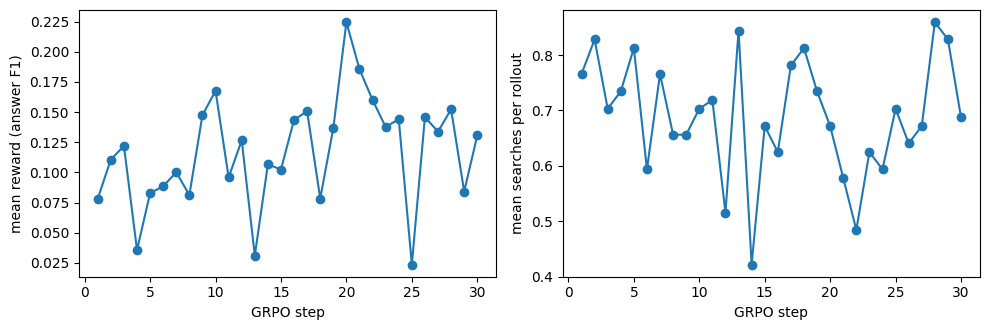

{"steps": 30, "sec_per_step": 7.258540391921997, "reward": [0.0782, 0.1107, 0.1219, 0.0356, 0.0828, 0.0885, 0.1001, 0.0812, 0.1474, 0.1676, 0.0958, 0.1266, 0.031, 0.1066, 0.1023, 0.1437, 0.1506, 0.0783, 0.1368, 0.2246, 0.1855, 0.16, 0.1376, 0.1441, 0.0235, 0.1458, 0.1338, 0.1523, 0.0841, 0.1306], "searches": [0.766, 0.828, 0.703, 0.734, 0.812, 0.594, 0.766, 0.656, 0.656, 0.703, 0.719, 0.516, 0.844, 0.422, 0.672, 0.625, 0.781, 0.812, 0.734, 0.672, 0.578, 0.484, 0.625, 0.594, 0.703, 0.641, 0.672, 0.859, 0.828, 0.688], "completion_len": [76, 78, 96, 96, 67, 80, 62, 65, 65, 55, 52, 39, 73, 38, 57, 48, 74, 53, 48, 47, 52, 45, 42, 40, 46, 40, 43, 54, 42, 45]}


In [2]:
import json
import os
import statistics

import matplotlib.pyplot as plt

RUN = f"{PROJECT}/checkpoints/grpo_Qwen2.5-0.5B-Instruct_smoke"
steps = [s for s in map(json.loads, open(f"{RUN}/log.jsonl")) if "reward" in s]
sec = [b["wall_s"] - a["wall_s"] for a, b in zip(steps, steps[1:])]  # step 1 also holds model and vLLM start-up
per_step = statistics.median(sec) if sec else float("nan")
skey = next((k for k in steps[-1] if "searches_mean" in k), None)
print(f"{len(steps)} steps, median {per_step:.0f} s/step")
print(f"projected 200-step stage 1: {200 * per_step / 3600:.1f} A100 hours, about {200 * per_step / 3600 * 5.4:.0f} compute units")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot([s["step"] for s in steps], [s["reward"] for s in steps], marker="o")
ax[0].set(xlabel="GRPO step", ylabel="mean reward (answer F1)")
if skey:
    ax[1].plot([s["step"] for s in steps], [s[skey] for s in steps], marker="o")
    ax[1].set(xlabel="GRPO step", ylabel="mean searches per rollout")
fig.tight_layout()
os.makedirs(f"{OUT}/figures", exist_ok=True)
fig.savefig(f"{OUT}/figures/grpo_smoke.png", dpi=200)
plt.show()

summary = {"steps": len(steps), "sec_per_step": per_step,
           "reward": [round(s["reward"], 4) for s in steps],
           "searches": [round(s[skey], 3) for s in steps] if skey else None,
           "completion_len": [round(s.get("completions/mean_length", 0)) for s in steps]}
print(json.dumps(summary))


In [ ]:
from google.colab import runtime
runtime.unassign()